# V02: Access a bucket and Autonomous Database from the customer VCN

Read a small CSV from a private Object Storage bucket and query an existing Autonomous Database through the same approved customer VCN. The workspace, bucket, database public endpoint and service gateway are in one OCI region. Create a dedicated test bucket in your chosen compartment; reuse the database.


This notebook is an unexecuted sample.


## How the source restrictions work

| Target | Who authenticates? | What restricts the connection source? | Successful operation |
| --- | --- | --- | --- |
| Object Storage | AIDP resource principal, selected by a dynamic group | IAM policy condition `request.networkSource.name='aidp_v02_vcn'` | Read the exact CSV rows. |
| Autonomous Database public endpoint | Existing database user through an approved catalog or wallet connection | The database's **VCN access control list**, plus database login privileges | Return the expected database service and session details from `DUAL`. |

A Network Source is an IAM definition of allowed request origins; it does not connect to a service or grant access by itself. For the bucket, the policy combines **identity + named bucket + allowed source**. The service-gateway path supplies the customer VCN/source context.

The database check uses a password-authenticated SQL connection. Its VCN ACL is configured separately: the IAM Network Source name is **not** an ADB SQL access rule. Putting `request.networkSource.name` on an `autonomous-databases` management policy does not restrict this SQL session. This notebook tests two source controls for the same customer network and reports their results separately.


## Before you begin

Have the AIDP administrator confirm the native `oci://` reader's effective identity. This walkthrough selects the AIDP instance resource principal; a dynamic-group rule cannot change a reader that actually uses user credentials.

Record the following before starting compute:

| Value | Obtain from |
| --- | --- |
| `<TEST_COMPARTMENT_ID>` | The compartment for the new bucket and existing database. |
| `<AIDP_RESOURCE_ID>`, `<IAM_DOMAIN>` | AIDP instance OCID and the dynamic group's identity domain. |
| `<CUSTOMER_VCN_ID>`, `<SOURCE_SUBNET_CIDR>` | Workspace private-connection VCN and actual customer-side source subnet. |
| `<BUCKET_NAME>`, namespace, object key | New private bucket and the supplied `fixtures/sample.csv`; it contains two rows and is 24 bytes. |
| ADB public hostname, port and service name | **Database connection > Public endpoint** for the existing ADB. Copy the selected descriptor's service name, not the display name. |
| Catalog key, or wallet ZIP/TNS/user | An approved connection to that **public endpoint**. Verify the effective descriptor before setting `public_endpoint_confirmed=True`. |

Keep secrets out of notebook cells and outputs. Prefer an existing catalog. If using a wallet, supply the password through a private runtime `ADB_PASSWORD` environment variable. Do not download credentials into the test bucket.


## IAM and database setup

Complete these steps before the reads. The notebook does not create policies or change the database.

### 1. Verify the operator's setup permissions

An IAM administrator creates the dynamic group, Network Source and bucket policy. A bucket owner creates the private bucket and uploads `sample.csv`. A database owner verifies the ACL and connection.

Creating a Network Source requires `NETWORK_SOURCE_CREATE` at the tenancy root. For a setup group in the same tenancy, an administrator can delegate management with:

```text
Allow group <IAM_DOMAIN>/<SETUP_OPERATORS> to manage network-sources in tenancy
```

For an operator from another tenancy, verify corresponding **Endorse** and **Admit** grants. A local `Allow any-user` statement does not replace cross-tenancy authorization. Being able to list Network Sources does not prove permission to create them. If creation fails, check the caller, tenancy root, home region and failed request ID.

### 2. Select the bucket reader with a dynamic group

Create `aidp_v02_reader` in **Identity & Security > Domains > your domain > Dynamic groups**, using:

```text
ALL {resource.id = '<AIDP_RESOURCE_ID>'}
```

Use the AIDP **instance OCID**, not a workspace/compute UUID or an `instance.id` rule for a Compute VM. In a tenancy without identity domains, use **Identity & Security > Dynamic Groups**.

### 3. Define the Network Source

In the tenancy's **home region**, open **Identity & Security > Network Sources**. Create or verify:

| Field | Value |
| --- | --- |
| Name | `aidp_v02_vcn` |
| Placement | Tenancy root; API `compartmentId` must be `<TENANCY_OCID>`. |
| Network type | Virtual Cloud Network |
| VCN OCID | `<CUSTOMER_VCN_ID>` |
| IP address/CIDR | `<SOURCE_SUBNET_CIDR>`, for example `10.20.1.0/24` |
| Public sources | Empty |

The VCN and range are a pair. Enter the **source subnet**, not an Object Storage destination address.

### 4. Grant reads from that source to the new bucket

In the test compartment or an authorized ancestor, create:

```text
Allow dynamic-group <IAM_DOMAIN>/aidp_v02_reader to read objects in compartment id <TEST_COMPARTMENT_ID> where all {target.bucket.name='<BUCKET_NAME>', request.networkSource.name='aidp_v02_vcn'}
Allow dynamic-group <IAM_DOMAIN>/aidp_v02_reader to read buckets in compartment id <TEST_COMPARTMENT_ID> where all {target.bucket.name='<BUCKET_NAME>', request.networkSource.name='aidp_v02_vcn'}
```

For a tenancy without identity domains, omit `<IAM_DOMAIN>/`. This grants object reads/listing and bucket metadata checks, not writes.

**Check overlapping grants before claiming enforcement.** A new bucket still inherits compartment/tenancy policies. A broad object grant through another dynamic group can authorize reads outside the Network Source. The IAM owner must exclude the test bucket from such grants or provide an otherwise isolated reader. Preserve shared access to other buckets. Until this is resolved, label the restriction test **BLOCKED**, even if the CSV read succeeds. Allow IAM and dynamic-group changes to propagate before testing.

### 5. Restrict the ADB public endpoint to the customer VCN

Open the existing ADB's **Network > Access control list > Edit**. Verify an approved **Virtual cloud network** entry for `<CUSTOMER_VCN_ID>`. Optionally specify `<SOURCE_SUBNET_CIDR>` to restrict clients further. Review existing consumers before tightening an ACL; preserve approved entries and any existing private endpoint.

Use an existing database account with `CREATE SESSION`; the query reads `DUAL` and changes no data. No `manage autonomous-databases` or `use database-connections` grant is needed for this password-authenticated SQL session. Database-management IAM permissions are required only for an administrator changing the database configuration. IAM token authentication would require a separate database integration and is not used here.

If the database has both public and private access, select **Public endpoint** explicitly. A successful query through the private descriptor does not validate this public-endpoint VCN ACL.


## Network setup

| Component | Required configuration |
| --- | --- |
| Workspace | Existing private connection to the recorded customer VCN/subnet. |
| Service gateway | **All services in the regional Oracle Services Network**, covering Object Storage and the ADB public endpoint. An Object Storage-only gateway label is insufficient for both checks. |
| Source subnet route | Destination type **Service**, matching the regional All Services label, target the service gateway. |
| Egress | Stateful TCP 443 for Object Storage and the ADB descriptor's TCP port, commonly 1521 for TLS or 1522 for mTLS. Retain applicable workspace prerequisites and return traffic. |
| Workspace hostnames | Exact Object Storage hostname and ADB **public** hostname used by the clients. Retain the original hostnames for TLS identity verification. |

Application paths:

- AIDP -> workspace private connection -> customer subnet -> service gateway -> Object Storage -> IAM Network Source check.
- AIDP -> workspace private connection -> customer subnet -> service gateway -> ADB public endpoint -> VCN ACL and database login.


### Example network topology

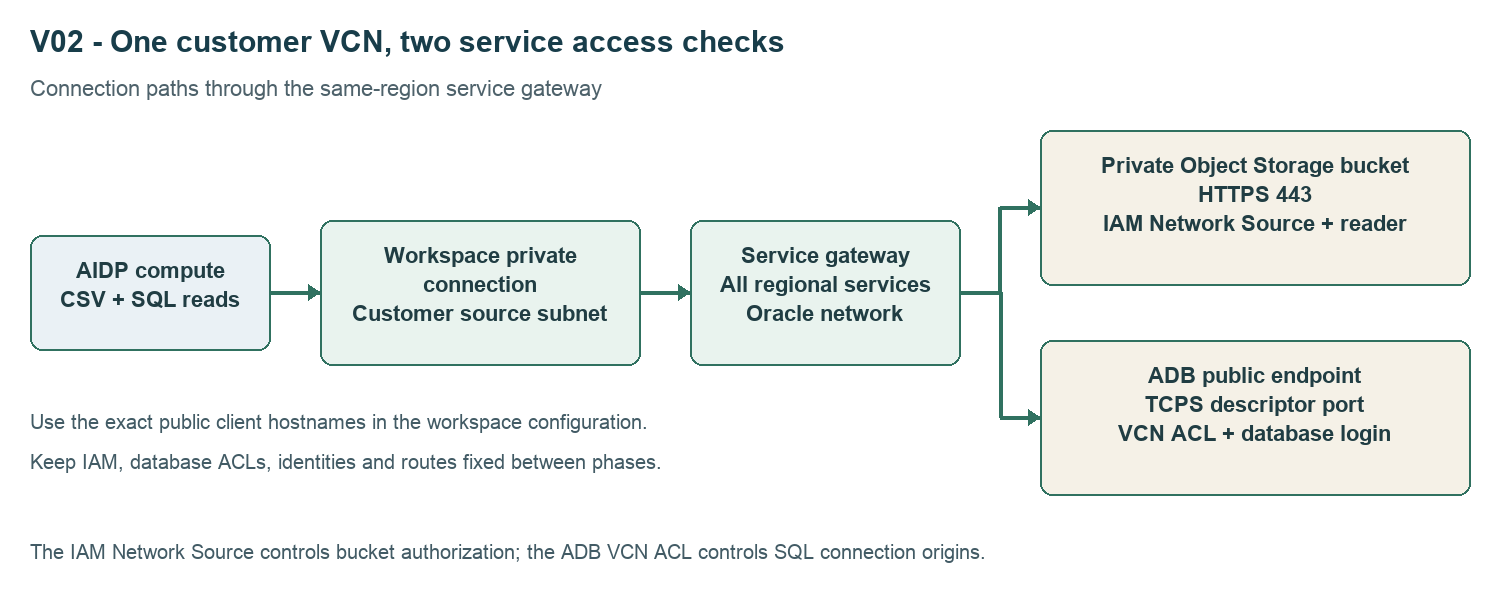

The diagram is illustrative; it does not prove the route taken by a request.


## Customer steps

1. **Prepare and record.** Complete IAM, bucket, ADB and network setup. Record all existing DNS/SCAN entries. If a target hostname is already present, preserve it and label that target as an existing-configuration validation.
2. **Initialize and configure.** Attach the approved compute. Run the code cell under **Initialize V02** and wait for **V02 initialized**. Fill `CONFIG` for the CSV and `ADB_CONFIG` for the database. Verify the catalog/wallet public descriptor; set its exact hostname, port and service, then set `public_endpoint_confirmed=True`. Run **Your configuration**.
3. **Run the baseline.** In **Choose phase**, set `RUN_LIVE=True` and `PHASE="before"` and run that cell. Run **Read the bucket object** and **Query the database**. Save both results; their outcomes may differ.
4. **Apply the missing hostname entries.** Edit the workspace's **Advanced options** and add only the two exact client hostnames that are missing. Preserve all existing entries. Follow any required compute-stop action, save, and reopen to verify. Keep IAM, ACLs, identities and routes unchanged.
5. **Repeat both operations.** Set `PHASE="after_add"` and rerun both read cells. Expect the exact CSV rows and the expected database service. Refresh connections after DNS caching as needed. Export earlier results before any required session restart.
6. **Restore and compare.** Remove only entries introduced by this test. Set `PHASE="restored"`, repeat both reads, and export. Leave pre-existing entries intact. Stop compute if you started it solely for this test.

Use **Choose phase** between attempts; rerunning the configuration cell clears results. Keep the test bucket until evidence is reviewed, then have its owner remove the fixture and bucket. Preserve the reused database and catalog.

**After a session restart or compute reattachment:** rerun **Initialize V02**, **Your configuration**, and **Choose phase** before either read cell. Restore your intended phase and live flag. Earlier in-memory results are lost after a session restart, so export them beforehand.

**If a read reports that V02 is not initialized:** run the code cell under **Initialize V02**, wait for its confirmation, and retry the read. Initialization alone preserves any configuration and results still in the current session. This is a notebook execution-order issue; the read has not reached Object Storage or ADB.


## Initialize V02

**Required:** attach your compute and run the code cell immediately below. Wait for **V02 initialized** before continuing to **Your configuration**. This cell defines the bucket and database checks; it makes no network calls. Run it again after a session restart or compute reattachment. Rerunning initialization preserves your configuration and collected results.


In [ ]:
CASE_NAMES = {'V02': 'Bucket and ADB access from the customer VCN'}

import argparse
import collections
import datetime
import hashlib
import json
import socket
import time
from pathlib import Path
from urllib.parse import urlsplit

class Prerequisite(Exception):
    pass

def utc():
    return datetime.datetime.now(datetime.timezone.utc).isoformat()

def canonical(value):
    return json.dumps(value, sort_keys=True, separators=(',', ':'))

def endpoint_host(value):
    return urlsplit(value if '://' in value else 'https://' + value).hostname

def fixture_read(spark, cfg):
    """Bounded CSV check; connector options apply to this reader, not globally."""
    for key in ('uri', 'endpoint', 'expected_rows'):
        if not cfg.get(key):
            raise Prerequisite('Missing fixture ' + key)
    uri, endpoint = (cfg['uri'], cfg['endpoint'])
    if '?' in uri or '#' in uri or '?' in endpoint or ('#' in endpoint):
        raise Prerequisite('Use unsigned fixture and endpoint references')
    parsed_endpoint = urlsplit(endpoint if '://' in endpoint else 'https://' + endpoint)
    if parsed_endpoint.username is not None or parsed_endpoint.password is not None:
        raise Prerequisite('Endpoint must not contain embedded credentials')
    if not parsed_endpoint.hostname:
        raise Prerequisite('Missing endpoint hostname')
    expected = cfg['expected_rows']
    if not isinstance(expected, list) or not 1 <= len(expected) <= 100:
        raise Prerequisite('Supply 1 to 100 expected synthetic CSV rows')
    size = cfg.get('fixture_size_bytes')
    if not isinstance(size, int) or isinstance(size, bool) or (not 0 < size <= 65536):
        raise Prerequisite('Verify fixture size is between 1 byte and 64 KiB')
    reader = spark.read.option('header', 'true').option('inferSchema', 'false')
    if uri.startswith('oci://'):
        authority = uri.split('://', 1)[1].split('/', 1)[0]
        if authority.count('@') != 1:
            raise Prerequisite('OCI URI must specify bucket@namespace')
        bucket, namespace = authority.split('@')
        reader = reader.option('fs.oci.client.hostname.' + bucket + '.' + namespace, endpoint)
    else:
        raise Prerequisite('Use an oci:// bucket@namespace/object URI')
    rows = reader.csv(uri).limit(len(expected) + 1).collect()
    actual = [r.asDict() for r in rows]
    assert collections.Counter(map(canonical, actual)) == collections.Counter(map(canonical, expected)), 'Fixture content mismatch'
    return {'rows': len(actual), 'fixture_assertion': 'exact row multiset', 'configured_endpoint': endpoint}

def run_case(case, cfg, spark=None, runtime=None, live=False, phase='baseline', fixture_role='primary'):
    if case not in CASE_NAMES:
        raise ValueError('Unknown case')
    result = {'case': case, 'name': CASE_NAMES[case], 'utc': utc(), 'phase': phase, 'workspace_label': cfg.get('workspace_label'), 'compute_label': cfg.get('compute_label'), 'checks': {}, 'origin': 'harness'}
    checks = result['checks']

    def check(name, action):
        started = time.monotonic()
        try:
            checks[name] = {'status': 'PASS', 'detail': action()}
        except Prerequisite as exc:
            checks[name] = {'status': 'BLOCKED', 'reason': str(exc)}
        except Exception as exc:
            checks[name] = {'status': 'FAIL', 'error_type': type(exc).__name__}
        checks[name]['elapsed_seconds'] = round(time.monotonic() - started, 3)
    if not live:
        checks['execution'] = {'status': 'NOT_RUN', 'reason': 'Live execution disabled'}
        return result
    if spark is None:
        checks['execution'] = {'status': 'BLOCKED', 'reason': 'Existing Spark session required'}
        return result
    if not cfg.get('workspace_label') or not cfg.get('compute_label'):
        checks['execution'] = {'status': 'BLOCKED', 'reason': 'Record workspace and compute labels'}
        return result
    if not cfg.get('region') or not cfg.get('workspace_region') or cfg['region'] != cfg['workspace_region']:
        checks['fixture_region'] = {'status': 'BLOCKED', 'reason': 'The bucket must be in the workspace region'}
        return result

    def spark_control():
        value = spark.sql('SELECT 1').collect()[0][0]
        assert value == 1, 'Spark control query returned unexpected result'
        return {'select_1': value, 'application_id': spark.sparkContext.applicationId}
    check('spark_control', spark_control)
    host = cfg.get('hostname') or endpoint_host(cfg.get('endpoint', ''))
    if not host:
        checks['dns'] = {'status': 'BLOCKED', 'reason': 'Missing exact hostname'}
    else:
        check('dns', lambda: {'addresses': sorted({a[4][0] for a in socket.getaddrinfo(host, cfg.get('port', 443), type=socket.SOCK_STREAM)})})
        if cfg.get('probe_tcp', False):

            def tcp():
                with socket.create_connection((host, cfg.get('port', 443)), timeout=5):
                    return {'connected': True, 'tls_verified': False}
            check('tcp', tcp)
        else:
            checks['tcp'] = {'status': 'NOT_RUN'}
    check('functional', lambda: fixture_read(spark, cfg))
    checks['source_path'] = {'status': 'BLOCKED', 'reason': 'Independent path evidence required; successful read is insufficient'}
    return result

def summarize(result):
    """No overall acceptance PASS: case-specific evidence review remains explicit."""
    states = [v['status'] for v in result['checks'].values()]
    if 'FAIL' in states:
        return 'FAIL'
    if 'BLOCKED' in states:
        return 'BLOCKED'
    if 'NOT_RUN' in states:
        return 'INCOMPLETE'
    return 'REVIEW_REQUIRED'

# Copyright (c) 2026 Oracle and/or its affiliates.
# Licensed under the Universal Permissive License v 1.0 as shown at https://oss.oracle.com/licenses/upl/.
"""Bounded public-endpoint ADB check embedded in the standalone V02 notebook."""
import datetime
import socket


def run_adb_check(cfg, spark=None, runtime=None, live=False, phase='before'):
    """Query an existing connection; never change ACLs, IAM, credentials or data."""
    result = {'case': 'V02', 'target': 'adb', 'phase': phase,
              'utc': datetime.datetime.now(datetime.timezone.utc).isoformat(), 'checks': {}}
    checks = result['checks']
    if not live:
        checks['execution'] = {'status': 'NOT_RUN', 'reason': 'Live execution disabled'}
        return result
    missing = [k for k in ('workspace_label', 'compute_label', 'hostname', 'expected_service',
                           'workspace_region', 'region') if not cfg.get(k)]
    reason = ('Complete ADB configuration: ' + ', '.join(missing)) if missing else ''
    if cfg.get('region') != cfg.get('workspace_region'):
        reason = 'The database and workspace must be in the same region'
    if cfg.get('public_endpoint_confirmed') is not True:
        reason = 'Verify the catalog or wallet descriptor uses the intended public endpoint'
    if spark is None:
        reason = 'Existing Spark session required'
    if reason:
        checks['execution'] = {'status': 'BLOCKED', 'reason': reason}
        return result
    catalog = cfg.get('catalog_id')
    if not catalog and (not all(cfg.get(k) for k in ('wallet_zip', 'tns', 'user')) or
                        not (runtime or {}).get('adb_password')):
        checks['execution'] = {'status': 'BLOCKED', 'reason':
            'Use an existing catalog, or wallet ZIP/TNS/user and a private runtime password'}
        return result
    try:
        addresses = sorted({a[4][0] for a in socket.getaddrinfo(
            cfg['hostname'], cfg.get('port', 1522), type=socket.SOCK_STREAM)})
        checks['dns'] = {'status': 'PASS', 'addresses': addresses}
    except Exception as exc:
        checks['dns'] = {'status': 'FAIL', 'error_type': type(exc).__name__}
    query = ("SELECT sys_context('USERENV','SERVICE_NAME') AS SERVICE_NAME, "
             "sys_context('USERENV','SESSION_USER') AS SESSION_USER, "
             "sys_context('USERENV','IP_ADDRESS') AS CLIENT_IP FROM dual")
    try:
        reader = (spark.read.format('aidataplatform').option('type', 'ORACLE_ALH')
                  .option('schema', 'SYS').option('table', 'DUAL')
                  .option('pushdown.sql', query).option('login.timeout.seconds', '20'))
        if catalog:
            reader = reader.option('catalog.id', catalog)
        else:
            reader = (reader.option('wallet.path', cfg['wallet_zip']).option('tns', cfg['tns'])
                      .option('user.name', cfg['user'])
                      .option('password', runtime['adb_password']))
        rows = reader.load().limit(2).collect()
        assert len(rows) == 1, 'Expected one database identity row'
        row = {k.upper(): v for k, v in rows[0].asDict().items()}
        matches = str(row.get('SERVICE_NAME', '')).casefold() == cfg['expected_service'].casefold()
        checks['functional'] = {'status': 'PASS' if matches else 'FAIL',
            'service_matches': matches, 'service_name': row.get('SERVICE_NAME'),
            'database_user': row.get('SESSION_USER'), 'client_ip_seen_by_database': row.get('CLIENT_IP')}
    except Exception as exc:
        # Driver exceptions can include passwords and connection strings.
        checks['functional'] = {'status': 'FAIL', 'error_type': type(exc).__name__}
    checks['source_path'] = {'status': 'BLOCKED', 'reason':
        'Review the public descriptor, unchanged VCN ACL, service-gateway path and database session evidence'}
    result['authorization_control'] = 'ADB VCN ACL plus database login; not an IAM Network Source condition'
    result['transport_claim'] = 'An authenticated query does not independently establish mTLS'
    return result

print("V02 initialized. Next: Your configuration, Choose phase, then the bucket and database cells.")


## Your configuration

Complete the setup first. CONFIG selects the new bucket fixture; ADB_CONFIG selects the existing database public-endpoint connection. Set each target region to the workspace region. The expected CSV rows match sample.csv. Copy expected_service from the selected ADB descriptor. Keep credentials out of both dictionaries.


In [ ]:
CASE_ID = 'V02'
CONFIG = {'workspace_label': '',
 'compute_label': '',
 'hostname': '',
 'probe_tcp': False,
 'port': 443,
 'kind': 'csv',
 'uri': '',
 'endpoint': '',
 'region': '',
 'workspace_region': '',
 'fixture_size_bytes': 0,
 'expected_rows': [{'id': '1', 'label': 'alpha'}, {'id': '2', 'label': 'beta'}]}
ADB_CONFIG = {'workspace_label': '',
 'compute_label': '',
 'hostname': '',
 'port': 1522,
 'region': '',
 'workspace_region': '',
 'catalog_id': '',
 'wallet_zip': '',
 'tns': '',
 'user': '',
 'expected_service': '',
 'public_endpoint_confirmed': False}
RUN_LIVE = False
RUN_EVIDENCE_CHECKS = False
PHASE = "before"
RESULTS = []


## Choose phase

Change only the phase and live flag between attempts. Keep earlier RESULTS.


In [ ]:
RUN_LIVE = False  # Set True after completing IAM and network setup.
PHASE = "before"  # Then after_add and restored, following Customer steps.


## Read the bucket object

Run this cell once per phase. The same configured runtime identity must read the same object under the unchanged policy and Network Source.


In [ ]:
if not all(callable(globals().get(name)) for name in ('run_case', 'summarize')):
    raise RuntimeError('V02 is not initialized in this session. Run the code cell under "Initialize V02" and wait for "V02 initialized". Then rerun this cell. After a session restart, also rerun "Your configuration" and "Choose phase".')
if any(name not in globals() for name in ('CASE_ID', 'CONFIG', 'RUN_LIVE', 'PHASE', 'RESULTS')):
    raise RuntimeError('V02 configuration is missing. Complete and run "Your configuration", then "Choose phase", before running this cell.')

result = run_case(CASE_ID, CONFIG, spark=globals().get("spark"), live=RUN_LIVE, phase=PHASE)
result["target"] = "bucket"
result["acceptance"] = summarize(result)
RESULTS.append(result)
print(json.dumps(result, indent=2))


## Query the database

Run once per phase using the same approved public-endpoint connection. The query reads DUAL and returns service, database user and the client address observed by ADB. A catalog supplies its own credentials; the wallet alternative reads ADB_PASSWORD privately from the runtime environment. This checks the ADB VCN ACL path, not an IAM Network Source condition.


In [ ]:
if not all(callable(globals().get(name)) for name in ('run_adb_check', 'summarize')):
    raise RuntimeError('V02 is not initialized in this session. Run the code cell under "Initialize V02" and wait for "V02 initialized". Then rerun this cell. After a session restart, also rerun "Your configuration" and "Choose phase".')
if any(name not in globals() for name in ('CASE_ID', 'ADB_CONFIG', 'RUN_LIVE', 'PHASE', 'RESULTS')):
    raise RuntimeError('V02 configuration is missing. Complete and run "Your configuration", then "Choose phase", before running this cell.')

import os
adb_result = run_adb_check(ADB_CONFIG, spark=globals().get("spark"), runtime={"adb_password": os.environ.get("ADB_PASSWORD")}, live=RUN_LIVE, phase=PHASE)
adb_result["acceptance"] = summarize(adb_result)
RESULTS.append(adb_result)
print(json.dumps(adb_result, indent=2))


## Review the result

| Target | From the approved customer source | From a source outside its configured rule |
| --- | --- | --- |
| Bucket, same authorized reader and no bypass grant | Exact fixture rows | Object read denied by IAM |
| ADB public endpoint, same valid database login | Expected service and session details | Connection rejected by the ADB ACL |

A successful CSV read or SQL query alone does not prove source enforcement. For Object Storage, correlate the UTC time/object with **Read Access Events**, checking request ID and `principalId`; review effective IAM grants and service-gateway evidence. For ADB, retain the public descriptor, ACL snapshot, service-gateway evidence, returned service/user/client address, and a controlled outside-source comparison where available. A client address alone does not prove the VCN route. Missing best-effort logs, DNS errors and timeouts do not establish an IAM denial.

The notebook reports functional results separately and leaves `source_path` for evidence review. The SQL result does not claim that IAM Network Sources control database login, or that a client certificate was presented. If an authorized path already works at baseline, report existing-configuration validation rather than a deny-to-allow transition.

`functional: PASS` confirms the CSV rows or expected database service for the named target. `source_path: BLOCKED` means that the policy/ACL and path evidence still needs human review. The following references document that review; they do not automatically query or validate IAM.


In [ ]:
EVIDENCE = {'evidence_ref': None,
 'runtime_principal_id': '',
 'dynamic_group_rule_ref': '',
 'network_source_name': '',
 'network_source_snapshot_ref': '',
 'bucket_policy_snapshot_ref': '',
 'effective_grants_review_ref': '',
 'route_snapshot_ref': '',
 'dns_before_ref': '',
 'dns_after_ref': '',
 'dns_restored_ref': '',
 'read_request_refs': [],
 'adb_public_descriptor_ref': '',
 'adb_acl_snapshot_ref': '',
 'adb_session_refs': [],
 'outside_source_comparison_refs': []}


## Export

Save this output privately with your configuration snapshots and request records.


In [ ]:
print(json.dumps({"case": CASE_ID, "generated_utc": utc(), "results": RESULTS, "evidence": EVIDENCE}, indent=2))


## References

- [Network Sources](https://docs.oracle.com/en-us/iaas/Content/Identity/Tasks/managingnetworksources.htm)
- [Network Source setup permissions](https://docs.oracle.com/en-us/iaas/Content/Identity/policyreference/iampolicyreference.htm)
- [Cross-tenancy operator policies](https://docs.oracle.com/en-us/iaas/Content/Identity/policieshow/iam-cross-domain.htm)
- [Dynamic-group matching rules](https://docs.oracle.com/en-us/iaas/Content/Identity/dynamicgroups/Writing_Matching_Rules_to_Define_Dynamic_Groups.htm)
- [Object Storage permissions](https://docs.oracle.com/en-us/iaas/Content/Identity/Reference/objectstoragepolicyreference.htm)
- [Object Storage request log fields](https://docs.oracle.com/en-us/iaas/Content/Logging/Reference/details_for_object_storage.htm)
- [ADB VCN access-control rules](https://docs.oracle.com/en-us/iaas/autonomous-database-serverless/doc/access-control-rules-autonomous.html)
- [Service gateway](https://docs.oracle.com/en-us/iaas/Content/Network/Tasks/servicegateway.htm)

Copyright (c) 2026 Oracle and/or its affiliates. Licensed under the [Universal Permissive License](../../LICENSE.txt), Version 1.0.
